Descriptive statistics basically means showing how a dataset looks.it gives a general description of quantitative data.
These are also called measures of central tendancy is central data is worked out in this case.

* Mean: The average of the data.

* Median: The central data point.

* Mode: The most repeated value.

In [92]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

In [93]:
goals = np.array([0, 1, 2, 1, 0, 3, 1, 2, 0, 1, 4, 2, 1, 0, 5, 1, 0, 2, 8])
counts = pd.Series(goals).value_counts().sort_index()

mean = np.mean(goals).round(4)
print("Mean:",mean)


sorted = np.sort(goals)
median = np.median(sorted)
print("Median:",median)

variance = np.var(goals,ddof = 1).round(4)
print(variance)

std = np.std(goals,ddof = 1).round(4)
print(std)

df = pd.Series(goals)
print(df.value_counts())

mode_value = df.mode()[0] #To pick up the first mode value mode is 1
print("Mode:", mode_value)

Mean: 1.7895
Median: 1.0
4.1754
2.0434
1    6
0    5
2    4
3    1
4    1
5    1
8    1
Name: count, dtype: int64
Mode: 1


* Skewness & Measures of Central Tendency
* Skewness shows which way the data is tilted. In other words, skewness basically reveals whether outliers are present or not.

* If data is positively or negatively skewed, we should look at the median for the central value, because we know the mean gets pulled too high or too low due to the presence of outliers.

* All of these are measures of central tendency, meaning they describe how the data behaves toward the center.

8
Skewness : 1.8458910463218874


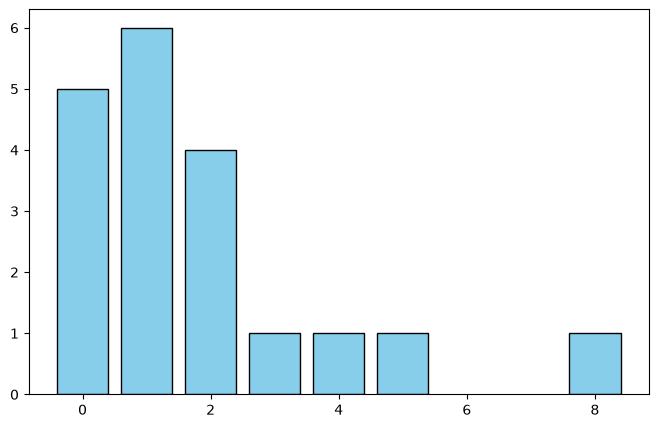

In [94]:
plt.figure(figsize=(8, 5))
plt.bar(counts.index, counts.values, color='skyblue', edgecolor='black')

range = np.max(goals) - np.min(goals)
print(range)

#We have Positively Skewed value here

skewness_value = df.skew()
print("Skewness :", skewness_value)

Right Skew (Positive): The Mean is greater than the Median Mean > Meadian because the high outliers pull the average up into the right tail.Left Skew (Negative): The Mean is less than the Median Mean < Median because low outliers pull the average down into the left tail.

Text(0.5, 0, 'Goals')

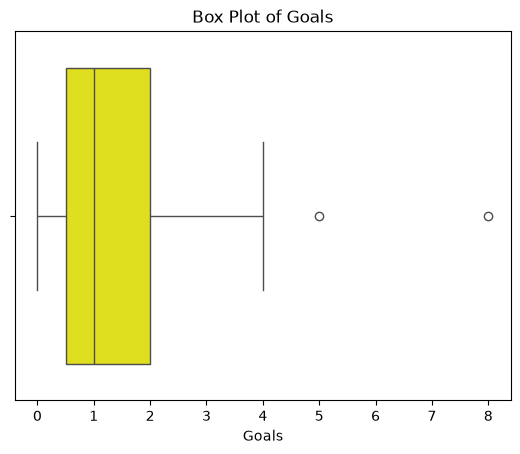

In [95]:
sns.boxplot(x = df , color = 'Yellow')
plt.title("Box Plot of Goals")
plt.xlabel("Goals")

* Measures of Dispersion

* Range: The difference between the largest and smallest values. It shows how spread out the data is. However, just because a range is high doesn't mean the whole dataset is generally spread out—it can simply mean that outliers are present.

* Variance: Shows how far away each data point is from the mean.

* Standard Deviation (std): Simply the square root of variance, serving the exact same purpose (in the original units).

In [96]:
range = np.max(goals) - np.min(goals)
print("Range: ",range)

variance = np.var(goals,ddof = 1)
print(variance)

stdev = np.std(goals,ddof = 1)
print(stdev)

#On average, the matches deviate from the mean by about 2.04 goals (Standard Deviation).

Range:  8
4.175438596491229
2.0433889978394295


* ddof=0 (Population): Divides by n. Use this only if your dataset contains every single data point that could ever possibly exist.
* ddof=1 (Sample): Divides by n - 1 (called Bessel's correction). Use this whenever you are working with a sample of real-world data (like your 19 football matches), because it corrects the math to prevent your variance from being biased.  

* IQR stands for Interquartile Range.
The middle 50% of the data

In [97]:
q1,q2,q3 = np.percentile(goals,[25,50,75])

InQuRa = q3 - q1
print(InQuRa)

LL = q1 - InQuRa * 1.5
UL = q3 + InQuRa * 1.5

print(LL,UL)


1.5
-1.75 4.25


<Axes: ylabel='Count'>

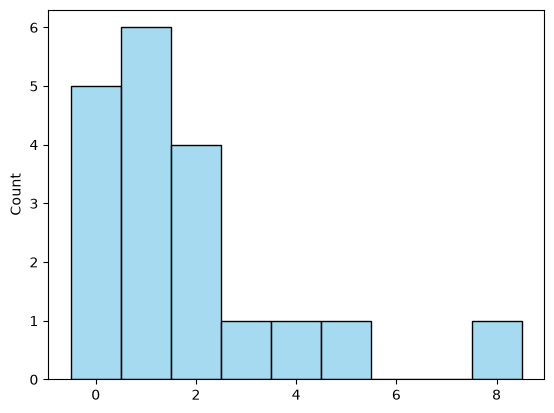

In [98]:
sns.histplot(
    goals, 
    discrete=True, 
    color='skyblue', 
    edgecolor='black'
)

In [99]:
df = pd.read_csv(r"C:\Users\Anbit Bhattarai\Desktop\Stats_For_AI_ML\football_practice.csv")
pd.set_option('display.width', 1000)

print(df.info)

<bound method DataFrame.info of            date  home_team    away_team  home_score  away_score                    tournament          city               country  neutral
0    2010-01-04    Germany       France           1           1  FIFA World Cup qualification        Munich               Germany    False
1    2010-01-26      India        Egypt           0           3                      Friendly      Istanbul                Turkey     True
2    2010-01-26      India  South Korea           1           3                      Friendly       Kolkata                 India    False
3    2010-03-10      India          USA           0           0                FIFA World Cup         Miami         United States     True
4    2010-04-09     Bhutan        Spain           0           3                      Friendly           NaN         United States     True
..          ...        ...          ...         ...         ...                           ...           ...                   ...     

In [100]:
print(df.isna().sum())

df["city"].fillna("Berlin")


date          0
home_team     0
away_team     0
home_score    0
away_score    0
tournament    0
city          5
country       0
neutral       0
dtype: int64


0            Munich
1          Istanbul
2           Kolkata
3             Miami
4            Berlin
           ...     
395    Buenos Aires
396           Dakar
397           Dubai
398          Zagreb
399          Lisbon
Name: city, Length: 400, dtype: str

In [101]:
print(df.duplicated().sum())
df.drop_duplicates()

2


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,2010-01-04,Germany,France,1,1,FIFA World Cup qualification,Munich,Germany,False
1,2010-01-26,India,Egypt,0,3,Friendly,Istanbul,Turkey,True
2,2010-01-26,India,South Korea,1,3,Friendly,Kolkata,India,False
3,2010-03-10,India,USA,0,0,FIFA World Cup,Miami,United States,True
4,2010-04-09,Bhutan,Spain,0,3,Friendly,NaN,United States,True
...,...,...,...,...,...,...,...,...,...
395,2024-11-11,Argentina,Sri Lanka,2,0,UEFA Nations League,Buenos Aires,Argentina,False
396,2024-11-16,Senegal,Egypt,1,0,Friendly,Dakar,Senegal,False
397,2024-11-22,USA,England,1,1,Copa America,Dubai,United Arab Emirates,True
398,2024-12-20,Croatia,France,1,2,Friendly,Zagreb,Croatia,False


In [102]:
df["date"] = pd.to_datetime(df["date"])
print(df)

          date  home_team    away_team  home_score  away_score                    tournament          city               country  neutral
0   2010-01-04    Germany       France           1           1  FIFA World Cup qualification        Munich               Germany    False
1   2010-01-26      India        Egypt           0           3                      Friendly      Istanbul                Turkey     True
2   2010-01-26      India  South Korea           1           3                      Friendly       Kolkata                 India    False
3   2010-03-10      India          USA           0           0                FIFA World Cup         Miami         United States     True
4   2010-04-09     Bhutan        Spain           0           3                      Friendly           NaN         United States     True
..         ...        ...          ...         ...         ...                           ...           ...                   ...      ...
395 2024-11-11  Argentina    Sri L

In [103]:
print(df["home_score"].describe())
print(df["away_score"].describe())

count    400.000000
mean       1.282500
std        1.127329
min        0.000000
25%        0.000000
50%        1.000000
75%        2.000000
max        6.000000
Name: home_score, dtype: float64
count    400.000000
mean       1.077500
std        1.097499
min        0.000000
25%        0.000000
50%        1.000000
75%        2.000000
max        7.000000
Name: away_score, dtype: float64


In [104]:
total_goals = df["home_score"].sum() + df["away_score"].sum()
print(total_goals)

goal_difference = df["home_score"].sum() - df["away_score"].sum()
print(goal_difference)

944
82


In [105]:
total_goals = df["home_score"] + df["away_score"]
print(total_goals)
print("Mean for total goals",np.mean(total_goals))
print("Median for total goals",np.median(total_goals))
print("Mode for total goals",total_goals.mode()[0])
print("Standard Deviation for total goals",total_goals.std().round(2))


print("For Home Goals")

print("Mean for home goals",df["home_score"].mean())
print("Median for home goals",df["home_score"].median())
print("Mode for home goals",df["home_score"].mode()[0])
print("Standard Deviation for Home goals",df["home_score"].std().round(2))



print("For Away Goals")

print("Mean for away goals",df["away_score"].mean())
print("Median for away goals",df["away_score"].median())
print("Mode for away goals",df["away_score"].mode()[0])
print("Standard Deviation for away goals",df["away_score"].std().round(2))






0      2
1      3
2      4
3      0
4      3
      ..
395    2
396    1
397    2
398    3
399    3
Length: 400, dtype: int64
Mean for total goals 2.36
Median for total goals 2.0
Mode for total goals 2
Standard Deviation for total goals 1.53
For Home Goals
Mean for home goals 1.2825
Median for home goals 1.0
Mode for home goals 1
Standard Deviation for Home goals 1.13
For Away Goals
Mean for away goals 1.0775
Median for away goals 1.0
Mode for away goals 1
Standard Deviation for away goals 1.1


In [106]:
LL = q1 - InQuRa * 1.5
UL = q3 + InQuRa * 1.5

print(LL,UL)

print((total_goals > 6).sum())

outliers = (total_goals > UL) | (total_goals < LL)
print(outliers.sum())

-1.75 4.25
4
28


In [107]:
print(df["home_score"].describe())
print(df["away_score"].describe())

count    400.000000
mean       1.282500
std        1.127329
min        0.000000
25%        0.000000
50%        1.000000
75%        2.000000
max        6.000000
Name: home_score, dtype: float64
count    400.000000
mean       1.077500
std        1.097499
min        0.000000
25%        0.000000
50%        1.000000
75%        2.000000
max        7.000000
Name: away_score, dtype: float64


In [108]:
tourney = df.groupby("tournament")
print(tourney["date"].count())
total_goals = tourney["home_score"].sum()+ tourney["away_score"].sum()
print(total_goals)
total_matches = tourney["date"].count()

meany = total_goals/total_matches
print(meany.head(5))

tournament
AFC Asian Cup                    24
African Cup of Nations           16
Copa America                     27
FIFA World Cup                   25
FIFA World Cup qualification     79
Friendly                        166
UEFA Euro qualification          32
UEFA Nations League              31
Name: date, dtype: int64
tournament
AFC Asian Cup                    59
African Cup of Nations           42
Copa America                     61
FIFA World Cup                   70
FIFA World Cup qualification    206
Friendly                        374
UEFA Euro qualification          70
UEFA Nations League              62
dtype: int64
tournament
AFC Asian Cup                   2.458333
African Cup of Nations          2.625000
Copa America                    2.259259
FIFA World Cup                  2.800000
FIFA World Cup qualification    2.607595
dtype: float64


In [109]:
turf = df.groupby("neutral")
print(turf.count())

home_advantage_df = df.groupby("neutral")[["home_score", "away_score"]].mean()

print(home_advantage_df)

         date  home_team  away_team  home_score  away_score  tournament  city  country
neutral                                                                               
False     309        309        309         309         309         309   307      309
True       91         91         91          91          91          91    88       91
         home_score  away_score
neutral                        
False      1.326861    1.051780
True       1.131868    1.164835


In [ ]:
tourney = df.groupby("tournament")["date"].count()
# print(tourney["date"].count())
# total_goals = tourney["home_score"].sum()+ tourney["away_score"].sum()
# print(total_goals)
# total_matches = tourney["date"].count()

# meany = total_goals/total_matches
# print(meany.head(5))

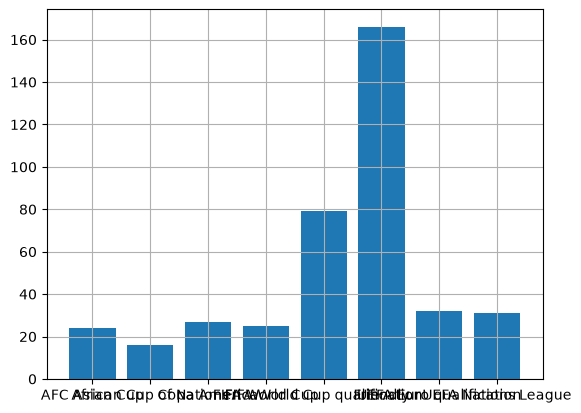

In [122]:
plt.bar(tourney.index,tourney.values)
plt.grid()

<BarContainer object of 400 artists>

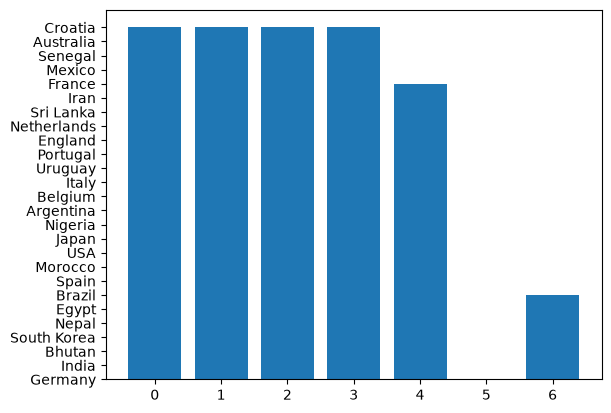

In [129]:
plt.bar(df["home_score"],df["home_team"])

# plt.bar(df["away_score"],df["home_team"])

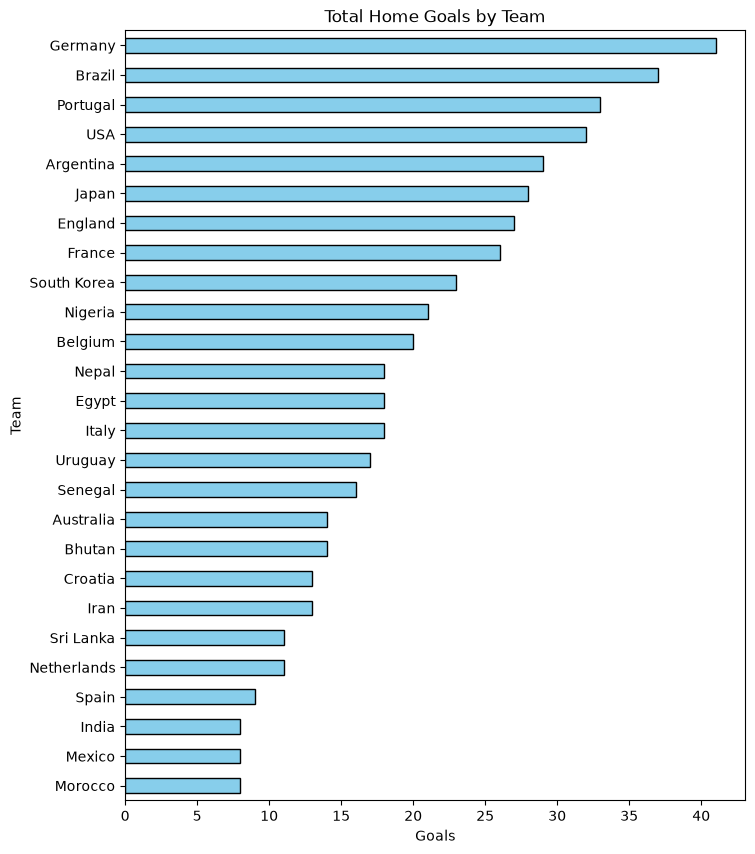

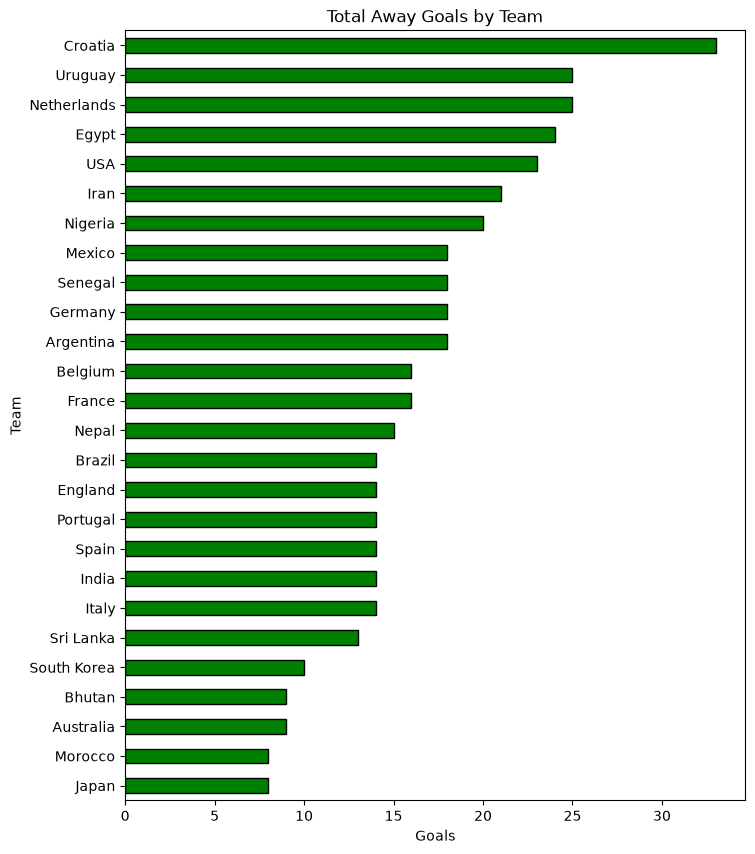

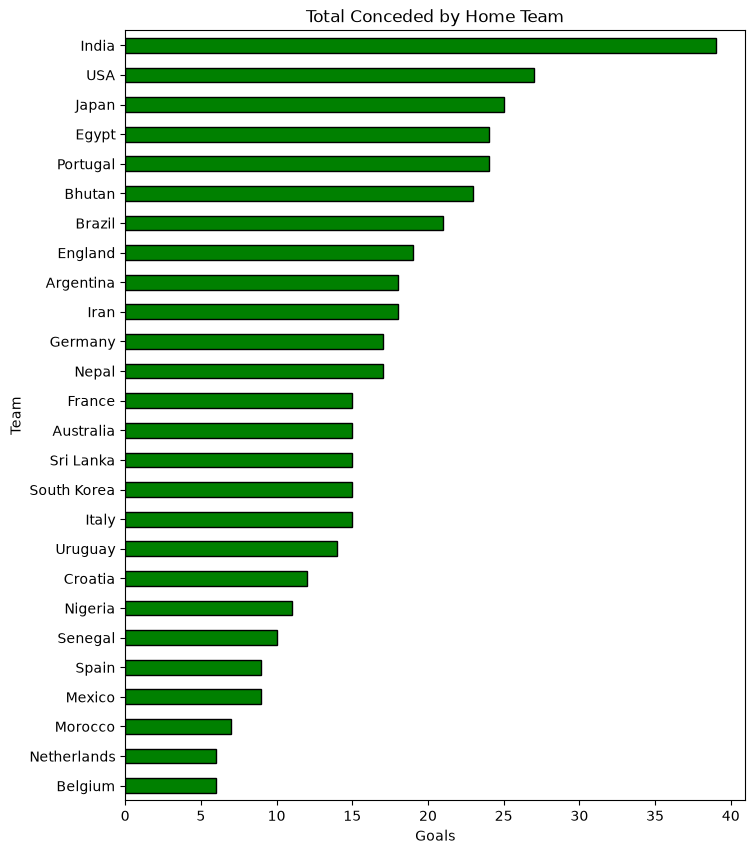

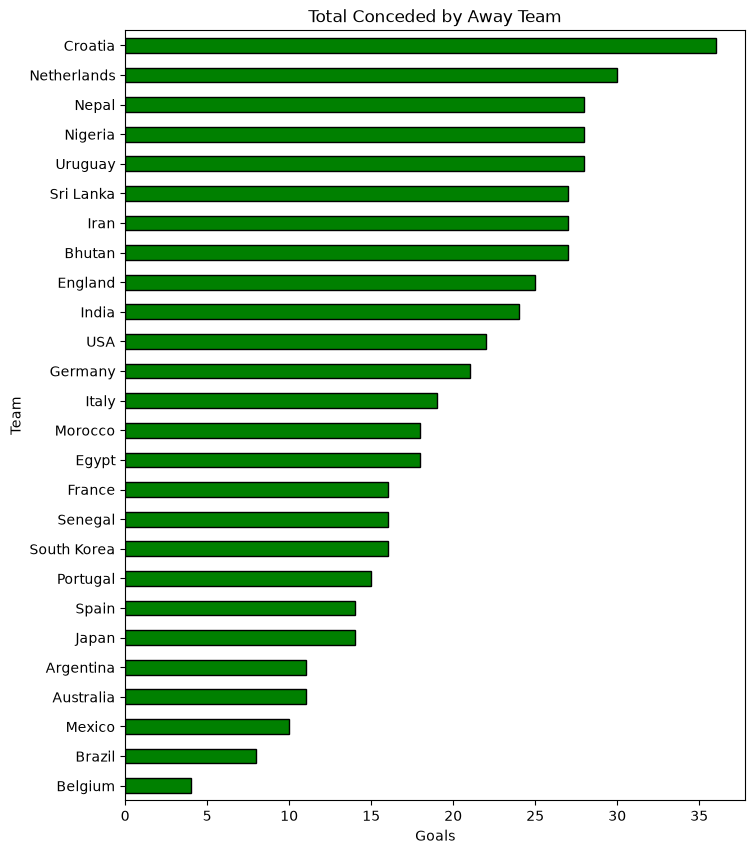

In [140]:
# Group by team and sum their home scores
team_goals = df.groupby("home_team")["home_score"].sum().sort_values(ascending=True)

# Plot a clean horizontal bar chart
plt.figure(figsize=(8, 10))
team_goals.plot(kind="barh", color="skyblue", edgecolor="black")

plt.title("Total Home Goals by Team")
plt.xlabel("Goals")
plt.ylabel("Team")
plt.show()

away_goals = df.groupby("away_team")["away_score"].sum().sort_values(ascending=True)
plt.figure(figsize = (8,10))
away_goals.plot(kind="barh",color = "Green",edgecolor = "black")
plt.title("Total Away Goals by Team")
plt.xlabel("Goals")
plt.ylabel("Team")
plt.show()

concededing = df.groupby("home_team")["away_score"].sum().sort_values(ascending=True)
plt.figure(figsize = (8,10))
concededing.plot(kind="barh",color = "Green",edgecolor = "black")
plt.title("Total Conceded by Home Team")
plt.xlabel("Goals")
plt.ylabel("Team")
plt.show()

concededing = df.groupby("away_team")["home_score"].sum().sort_values(ascending=True)
plt.figure(figsize = (8,10))
concededing.plot(kind="barh",color = "Green",edgecolor = "black")

plt.title("Total Conceded by Away Team")
plt.xlabel("Goals")
plt.ylabel("Team")
plt.show()

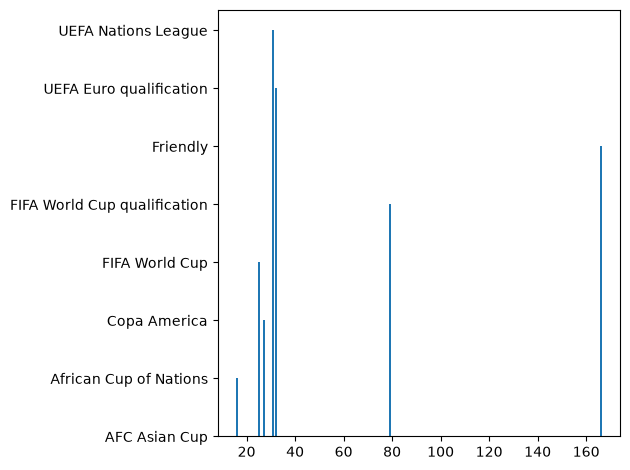

In [133]:
plt.bar(tourney.values,tourney.index)
plt.tight_layout()

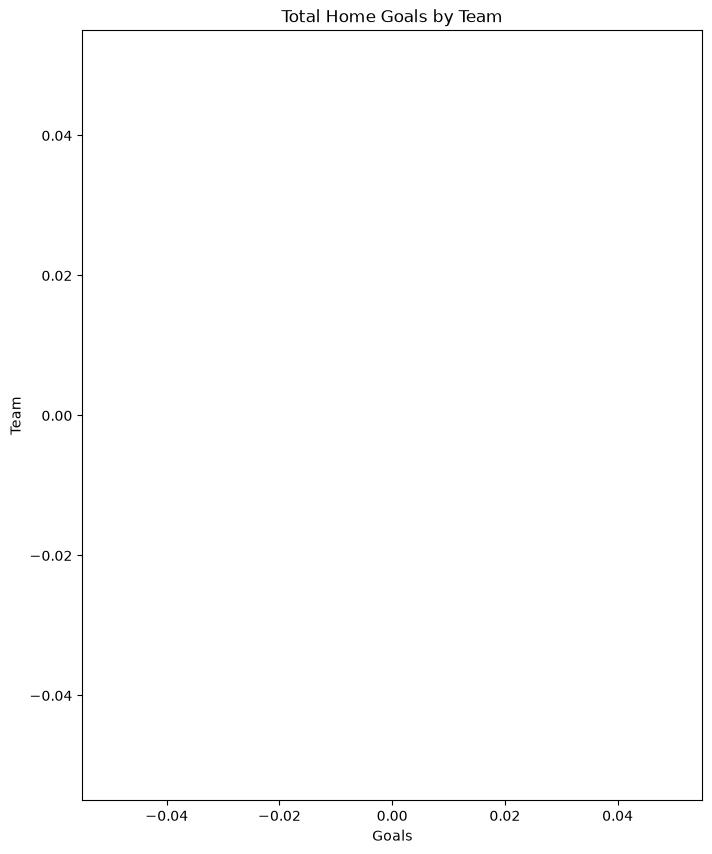